# Random Forests: Zero to Confident
## Heart Disease Risk Prediction Project

Welcome! This notebook is your complete, beginner-friendly journey into **Random Forests**. We assume you already know single decision trees (how they split data using thresholds to make predictions). Here, you will discover how combining many trees creates one of the most powerful and reliable algorithms in all of machine learning.

Every single concept follows our strict 7-step learning structure:
1. **The idea in ONE plain sentence**
2. **A real-life analogy**
3. **A tiny example with real numbers worked by hand**
4. **The math with EVERY symbol explained in words**
5. **The code explained line by line**
6. **One common beginner mistake**
7. **One quick 'check yourself' question** (with answer revealed inside a fold)

---

## 📚 Living Glossary of Terms
*Every new technical term is defined here in one plain sentence upon first appearance.*

- **Decision Tree**: A flowchart-like model that makes decisions by asking a series of yes/no questions about features.
- **Ensemble**: A collection of several machine learning models working together to produce a single stronger prediction.
- **Bias**: Error caused by making overly simplistic assumptions about the underlying data pattern.
- **Variance**: Error caused by being overly sensitive to random fluctuations or quirks in the training dataset.
- **Overfitting**: When a model memorizes training noise so closely that it fails on unseen test data.
- **Wisdom of the Crowd**: The statistical phenomenon where combining the independent guesses of many individuals is more accurate than any single individual.
- **Bootstrap Sampling**: Creating a new dataset by repeatedly drawing samples from the original dataset *with replacement*.
- **With Replacement**: Putting a sampled item back into the pool so it has a chance of being selected again.
- **Bagging (Bootstrap Aggregating)**: An ensemble technique where multiple models are trained on bootstrap samples and their outputs are combined by averaging or voting.
- **Feature Subsampling**: Restricting each tree or split to randomly choose among only a subset of available features.
- **Decorrelation**: Reducing the statistical dependency between individual tree predictions so they do not make the same mistakes simultaneously.
- **Pearson Correlation ($\rho$)**: A number between -1 and +1 measuring how closely two variables move together in tandem.


---
# Step 1: The Core Theory in Plain English
### Why Trees Need Friends, and How Averaging Breaks the Variance Trap

Before touching code, let's build rock-solid intuition for why single decision trees fail, why simple averaging rescues them, and why **feature subsampling** is the secret sauce of Random Forests.


### 1.1 Bias vs Variance: The Fundamental Tradeoff

#### 1. The Idea in ONE Plain Sentence
**Bias** is error from being too stubborn and simplistic, while **variance** is error from being too sensitive and overreacting to every bump in the training data.

#### 2. Real-Life Analogy
Imagine an archer shooting arrows at a bullseye:
- **High Bias (The Stubborn Archer)**: Always shoots tightly grouped arrows, but 6 inches to the upper right because the bow sight is misaligned.
- **High Variance (The Shaky Archer)**: The average position of all arrows is centered near the bullseye, but individual arrows scatter wildly all over the board.
- **Low Bias + High Variance**: An unconstrained, deep decision tree! It bends perfectly around every training point, but if you change even 3 patients in the training set, the tree's entire structure morphs completely.

#### 3. Tiny Example with Real Numbers Worked by Hand
Suppose a patient's true resting blood pressure is **130 mm Hg**.
- **Model A (High Bias)**: Always predicts **115 mm Hg** for all adult patients regardless of input.
  $$\text{Error} = |115 - 130| = 15 \text{ mm Hg every single time (inflexible)}.$$
- **Model B (High Variance - Unpruned Tree)**:
  - If trained on Dataset 1, it memorizes a noisy outlier and predicts **160 mm Hg**.
  - If trained on Dataset 2, it predicts **102 mm Hg**.
  - If trained on Dataset 3, it predicts **128 mm Hg**.
  - The predictions fluctuate wildly ($160, 102, 128$) across datasets, even though the average is near $130$.

#### 4. The Math with Every Symbol Explained in Words
> **Prerequisite Refresher (Expected Value)**:
> $\mathbb{E}[\hat{f}(x)]$ means the "average prediction" our model would make if we trained it on thousands of different random datasets drawn from the same population.

For any unseen test patient $x$ with true target $y = f(x) + \epsilon$ (where $\epsilon$ is irreducible random noise with mean $0$ and variance $\sigma^2_\epsilon$):
$$\text{Expected Test Mean Squared Error} = \underbrace{\Big(f(x) - \mathbb{E}[\hat{f}(x)]\Big)^2}_{\text{Bias}^2} + \underbrace{\mathbb{E}\left[\Big(\hat{f}(x) - \mathbb{E}[\hat{f}(x)]\Big)^2\right]}_{\text{Variance}} + \underbrace{\sigma^2_\epsilon}_{\text{Irreducible Noise}}$$

**Symbol definitions in plain words**:
- $f(x)$: The true underlying medical reality.
- $\hat{f}(x)$: The prediction our trained decision tree actually makes.
- $\mathbb{E}[\hat{f}(x)]$: The average prediction of trees across many different training sets.
- $\text{Bias}^2$: How far our average model is from the truth (stubbornness).
- $\text{Variance}$: How much predictions bounce around from one training set to another (instability).
- $\sigma^2_\epsilon$: Pure random randomness in nature (e.g. human biology fluctuating daily) that no model can predict.

Single deep decision trees have **low bias** (they can approximate complex boundaries) but **disastrously high variance**!

#### 5. Code Demonstration Line by Line
Let's see this instability in action. We fit 3 separate unpruned decision trees on 3 tiny random subsets of data and observe how wildly their predictions swing on the exact same patient.


**What we are about to do and why**:
We simulate a noisy medical signal and fit three unpruned single decision trees on 3 slightly different random splits of the same population. We will print the predictions for the exact same patient to show the high variance of single trees.

In [1]:
# Import essential tools for our demonstration
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

# Fix random seed so results are reproducible
np.random.seed(42)

# Generate a synthetic underlying truth: y = 2*x + noise
X_pop = np.linspace(0, 10, 100).reshape(-1, 1)
y_pop = 2.0 * X_pop.ravel() + np.random.normal(0, 2.0, size=100)

# Evaluate on one specific test point: x = 5.0 (True value ~ 10.0)
x_test = np.array([[5.0]])
predictions = []

# Fit 3 single unconstrained decision trees on 3 random subsets
for i in range(3):
    idx = np.random.choice(len(X_pop), size=40, replace=False)
    tree = DecisionTreeRegressor(max_depth=None, random_state=i)
    tree.fit(X_pop[idx], y_pop[idx])
    pred = tree.predict(x_test)[0]
    predictions.append(pred)
    print(f"Tree {i+1} prediction at x=5.0: {pred:.2f}")

print(f"Spread (Max - Min): {max(predictions) - min(predictions):.2f}")

Tree 1 prediction at x=5.0: 6.37
Tree 2 prediction at x=5.0: 6.37
Tree 3 prediction at x=5.0: 11.61
Spread (Max - Min): 5.24


**What we just saw**:
Even though the true value at $x = 5.0$ is approximately $10.0$, the three individual unpruned decision trees made predictions with a wide spread. Because each tree chased the noisy training points in its sample, their individual answers bounce around. This is **high variance** in the flesh!

#### 6. Common Beginner Mistake
Thinking that because a single tree achieves $100\%$ accuracy on training data, it is a superior model. In reality, a tree with $0$ training error is usually severely overfitted—it memorized the training noise and has massive variance on new patients!

#### 7. Quick Check Yourself Question
> **Question**: If a model has zero bias and zero variance, can its test error still be greater than zero?
>
> <details>
> <summary><b>Click to see the answer</b></summary>
> <b>Yes!</b> Even if both Bias and Variance are zero, irreducible noise ($\sigma^2_\epsilon$) remains. Real-world data contains inherent randomness (measurement errors, unmeasured variables) that cannot be eliminated by any algorithm.
> </details>


---
### 1.2 Why Averaging Reduces Variance (The Wisdom of the Crowd)

#### 1. The Idea in ONE Plain Sentence
Averaging the predictions of multiple independent models cancels out their individual random errors, shrinking the overall variance without hurting bias.

#### 2. Real-Life Analogy
In 1906, statistician Francis Galton visited a county fair where 787 people tried to guess the weight of an ox. Individual guesses were wildly inaccurate (some too high by 50 lbs, others too low by 40 lbs). But when Galton calculated the **average of all 787 guesses**, it came out to **1,207 lbs**—within 1 lb of the ox's true weight (1,198 lbs)! The errors canceled out.

#### 3. Tiny Example with Real Numbers Worked by Hand
Imagine 3 independent doctors guessing whether a tumor is benign or malignant on a scale of $0$ to $100$. The true value is **50**.
- Doctor 1 overestimates due to personal caution: **70** (error: $+20$)
- Doctor 2 underestimates due to a shadow: **30** (error: $-20$)
- Doctor 3 is close: **50** (error: $0$)

$$\text{Average Guess} = \frac{70 + 30 + 50}{3} = \frac{150}{3} = 50.$$
The average is exactly on the bullseye!

Now let's compute the variance:
- Individual variance of the guesses:
  $$\sigma^2 = \frac{(70-50)^2 + (30-50)^2 + (50-50)^2}{3} = \frac{400 + 400 + 0}{3} = \frac{800}{3} \approx 266.7$$
- If we took many groups of 3 doctors and averaged each group, the variance of the group averages would be:
  $$\text{Variance of Average} = \frac{\sigma^2}{3} = \frac{266.7}{3} \approx 88.9.$$
Variance was cut by a factor of 3!

#### 4. The Math with Every Symbol Explained in Words
> **Prerequisite Refresher (Variance Properties)**:
> 1. Scaling rule: $\text{Var}(c \cdot X) = c^2 \cdot \text{Var}(X)$ for any constant number $c$.
> 2. Addition rule for *independent* random variables: $\text{Var}(X_1 + X_2) = \text{Var}(X_1) + \text{Var}(X_2)$.

Suppose we have $B$ independent trees: $\hat{f}_1(x), \hat{f}_2(x), \dots, \hat{f}_B(x)$.
Each individual tree has the same variance: $\text{Var}(\hat{f}_i(x)) = \sigma^2$.
We define the ensemble prediction as the simple average:
$$\bar{f}(x) = \frac{1}{B} \sum_{i=1}^B \hat{f}_i(x)$$

Let's derive the variance of this average step-by-step:

| Step | Mathematical Expression | Plain-English Explanation |
| :--- | :--- | :--- |
| **Step 1** | $\text{Var}(\bar{f}(x)) = \text{Var}\left(\frac{1}{B}\sum_{i=1}^B \hat{f}_i(x)\right)$ | Write out the variance of the ensemble average. |
| **Step 2** | $= \left(\frac{1}{B}\right)^2 \text{Var}\left(\sum_{i=1}^B \hat{f}_i(x)\right)$ | Pull the constant factor $\frac{1}{B}$ outside, squaring it ($c^2$). |
| **Step 3** | $= \frac{1}{B^2} \sum_{i=1}^B \text{Var}(\hat{f}_i(x))$ | Because the trees are independent, the variance of the sum is the sum of variances. |
| **Step 4** | $= \frac{1}{B^2} \cdot (B \cdot \sigma^2)$ | Adding $\sigma^2$ together $B$ times gives $B \cdot \sigma^2$. |
| **Step 5** | $= \frac{\sigma^2}{B}$ | Cancel $B$ from top and bottom. |

$$\mathbf{\text{Var}(\bar{f}(x)) = \frac{\sigma^2}{B}}$$

**Key Insight**: If we can create $100$ independent trees, our prediction variance is divided by $100$!

#### 5. Code Demonstration Line by Line
Let's verify this mathematical formula empirically by averaging $B$ independent simulated estimators.


**What we are about to do and why**:
We simulate 1,000 trials where we average $B$ independent random variables with variance $\sigma^2 = 9.0$. We will plot the empirical variance as $B$ grows and compare it directly against the theoretical curve $\sigma^2 / B$.

In [2]:
# Simulate independent random estimators to verify variance reduction
B_values = [1, 2, 5, 10, 20, 50, 100]
true_sigma2 = 9.0
n_simulations = 1000

empirical_variances = []
theoretical_variances = [true_sigma2 / b for b in B_values]

for b in B_values:
    # Generate 1000 repetitions of averaging b independent standard normal variables (sigma=3)
    estimates = np.random.normal(loc=0.0, scale=np.sqrt(true_sigma2), size=(n_simulations, b)).mean(axis=1)
    empirical_variances.append(np.var(estimates))

# Print side-by-side comparison
for b, emp, theo in zip(B_values, empirical_variances, theoretical_variances):
    print(f"B = {b:3d} trees | Empirical Var: {emp:6.3f} | Theoretical (sigma^2/B): {theo:6.3f}")

B =   1 trees | Empirical Var: 10.135 | Theoretical (sigma^2/B):  9.000
B =   2 trees | Empirical Var:  4.805 | Theoretical (sigma^2/B):  4.500
B =   5 trees | Empirical Var:  1.684 | Theoretical (sigma^2/B):  1.800
B =  10 trees | Empirical Var:  0.833 | Theoretical (sigma^2/B):  0.900
B =  20 trees | Empirical Var:  0.458 | Theoretical (sigma^2/B):  0.450
B =  50 trees | Empirical Var:  0.168 | Theoretical (sigma^2/B):  0.180
B = 100 trees | Empirical Var:  0.089 | Theoretical (sigma^2/B):  0.090


**What we just saw**:
The empirical simulation matches the math with pinpoint precision. When $B = 100$, the variance dropped from $9.0$ down to $\approx 0.09$!

#### 6. Common Beginner Mistake
Assuming that averaging models reduces **bias**. It does NOT!
$$\mathbb{E}[\bar{f}(x)] = \frac{1}{B}\sum_{i=1}^B \mathbb{E}[\hat{f}_i(x)] = \mathbb{E}[\hat{f}(x)].$$
If your base models have high bias (they are too simple, like depth-1 stumps that cannot see non-linear patterns), averaging 1,000 of them still leaves you with high bias! That is why Random Forests use **deep, unpruned trees** with very low bias and rely on averaging to tame their variance.

#### 7. Quick Check Yourself Question
> **Question**: If one single tree has variance 16, what is the variance of the average of 16 perfectly independent trees?
>
> <details>
> <summary><b>Click to see the answer</b></summary>
> <b>Variance = 1.0</b> (using $	ext{Var} = \sigma^2 / B = 16 / 16 = 1$).
> </details>


---
### 1.3 Bootstrap Sampling and Bagging (Bootstrap Aggregation)

#### 1. The Idea in ONE Plain Sentence
Since we only have one real-world training dataset, we create dozens of slightly different synthetic training datasets by randomly drawing samples **with replacement**.

#### 2. Real-Life Analogy
Imagine writing every patient's name on a slip of paper and putting all $N$ slips into a magician's hat.
To create a training set for Tree #1:
1. You close your eyes, draw a slip, and write the patient's name on Tree 1's roster.
2. **Crucial step**: You drop the slip **back into the hat** (replacement).
3. You draw again, repeating this $N$ times.

Because you put slips back, some lucky patients appear 2 or 3 times on the roster, while about one-third of the patients are never picked at all!

#### 3. Tiny Example with Real Numbers Worked by Hand
Suppose our original dataset has just 4 patients:
$$\mathcal{D} = [\text{Alice}, \text{Bob}, \text{Carol}, \text{David}].$$
We draw 4 times with replacement:
- Draw 1: Alice $\to$ write Alice, put Alice back.
- Draw 2: Bob $\to$ write Bob, put Bob back.
- Draw 3: Alice again! $\to$ write Alice, put Alice back.
- Draw 4: David $\to$ write David, put David back.

Bootstrap Sample: $[\text{Alice}, \text{Bob}, \text{Alice}, \text{David}]$.
Notice:
- Alice was picked twice ($50\%$ of the sample).
- Carol was **completely omitted** (she is "Out-Of-Bag" for this tree)!

#### 4. The Math with Every Symbol Explained in Words
What fraction of original samples get left out of a bootstrap sample of size $n$?
Let's calculate the probability that Patient #1 is **never selected** across all $n$ independent draws:

| Step | Expression | Plain-English Meaning |
| :--- | :--- | :--- |
| **Step 1** | $P(\text{not picked on draw 1}) = 1 - \frac{1}{n}$ | Out of $n$ slips in the hat, $n-1$ slips belong to other patients. |
| **Step 2** | $P(\text{not picked in all } n \text{ draws}) = \left(1 - \frac{1}{n}\right)^n$ | Each draw is independent, so we multiply the probabilities $n$ times. |
| **Step 3** | $\lim_{n \to \infty} \left(1 - \frac{1}{n}\right)^n = \frac{1}{e} \approx 0.3679$ | Standard mathematical limit of Euler's number $e$. |

**Result**: For any decent-sized dataset ($n \ge 100$), approximately:
- **$63.2\%$** of unique samples are included in each bootstrap sample.
- **$36.8\%$** of samples are left out (the **Out-Of-Bag (OOB)** samples).

#### 5. Code Demonstration Line by Line
Let's write a simple Python function to draw a bootstrap sample and count duplicates and omissions.


**What we are about to do and why**:
We create a synthetic dataset of 100 patient IDs and draw a bootstrap sample using `np.random.choice(..., replace=True)`. We check the percentage of unique patients included and left out to verify our 63.2% vs 36.8% mathematical proof.

In [3]:
# Demonstrate bootstrap sampling on 100 patient IDs
patient_ids = np.arange(100)

# Draw 100 samples WITH replacement
bootstrap_sample = np.random.choice(patient_ids, size=len(patient_ids), replace=True)

# Count unique patients picked and left out
unique_picked = np.unique(bootstrap_sample)
out_of_bag = np.setdiff1d(patient_ids, unique_picked)

print(f"Total draws: {len(bootstrap_sample)}")
print(f"Unique patients picked: {len(unique_picked)} ({len(unique_picked)}%)")
print(f"Patients left out (Out-Of-Bag): {len(out_of_bag)} ({len(out_of_bag)}%)")
print(f"Expected theoretical OOB: ~36.8%")

Total draws: 100
Unique patients picked: 64 (64%)
Patients left out (Out-Of-Bag): 36 (36%)
Expected theoretical OOB: ~36.8%


**What we just saw**:
Exactly as predicted by math, approximately $63\%$ of patients were picked (some multiple times) and $\approx 37\%$ were omitted. This omitted set will become our free validation set in Step 5!

#### 6. Common Beginner Mistake
Confusing **sampling without replacement** (like standard train/test splitting or k-fold CV) with **sampling with replacement** (bootstrap). If you sample $n$ items from $n$ without replacement, you just get the exact same dataset in a scrambled order!

#### 7. Quick Check Yourself Question
> **Question**: If you create 100 bootstrap datasets of size $N$ from an original dataset of size $N$, do you have $100 \times N$ completely new independent data points?
>
> <details>
> <summary><b>Click to see the answer</b></summary>
> <b>No!</b> You still only have $N$ unique pieces of ground-truth information. Bootstrap reshuffles and weights existing observations, creating pseudo-replicates, but cannot conjure new information out of thin air.
> </details>


---
### 1.4 The Irreducible Variance Floor: Why Feature Subsampling is the Key Ingredient

Now comes the critical theoretical insight of Random Forests. Bagging alone is **not enough**!

#### 1. The Idea in ONE Plain Sentence
Standard bagging produces trees that are heavily **correlated** because they all latch onto the same strongest feature; **feature subsampling** forces trees to look at different clues, breaking that correlation and unlocking dramatic variance reduction.

#### 2. Real-Life Analogy
Imagine a medical board of 10 doctors diagnosing a difficult patient.
- **Scenario A (Standard Bagging)**: All 10 doctors look at the patient's chart. One test result shows "Severe Chest Pain". Because chest pain is such an obvious, overwhelming symptom, all 10 doctors immediately start their diagnosis with chest pain. If chest pain turns out to be a red herring (e.g. acid reflux mimicking angina), **all 10 doctors make the exact same wrong diagnosis**! Their opinions were correlated.
- **Scenario B (Random Forest with Feature Subsampling)**: You give Doctor 1 only blood pressure and cholesterol. You give Doctor 2 only ECG results and age. You give Doctor 3 chest pain and blood sugar. Now, Doctor 1 and 2 are forced to find subtle secondary signals! When you poll the group, their mistakes are uncorrelated, and the group reaches the correct medical consensus.

#### 3. Tiny Example with Real Numbers Worked by Hand
Suppose we have two trees, Tree A and Tree B, each with variance $\sigma^2 = 10$.
We average their predictions: $\bar{f} = \frac{\text{Tree A} + \text{Tree B}}{2}$.
The variance of their average depends on their correlation $\rho$:
$$\text{Var}(\bar{f}) = \rho \sigma^2 + \frac{1-\rho}{2}\sigma^2.$$
- **Case 1 (High correlation $\rho = 0.90$, like Bagging)**:
  $$\text{Var}(\bar{f}) = (0.90)(10) + \frac{1 - 0.90}{2}(10) = 9.0 + 0.5 = \mathbf{9.5}.$$
  Averaging two trees barely helped! Variance only dropped from $10$ to $9.5$.
- **Case 2 (Low correlation $\rho = 0.20$, with Feature Subsampling)**:
  $$\text{Var}(\bar{f}) = (0.20)(10) + \frac{1 - 0.20}{2}(10) = 2.0 + 4.0 = \mathbf{6.0}.$$
  Variance dropped by $40\%$!

#### 4. The Math of Correlated Variables with Every Symbol Explained in Words
> **Prerequisite Refresher (Covariance & Correlation)**:
> - $\text{Cov}(X_i, X_j) = \mathbb{E}[(X_i - \mu)(X_j - \mu)]$ measures how much two variables deviate from their mean together.
> - Pearson correlation $\rho = \frac{\text{Cov}(X_i, X_j)}{\sigma^2}$, so $\text{Cov}(X_i, X_j) = \rho \sigma^2$.
> - General variance of a sum: $\text{Var}\left(\sum_{i=1}^B X_i\right) = \sum_{i=1}^B \text{Var}(X_i) + \sum_{i \ne j} \text{Cov}(X_i, X_j)$.

Now consider $B$ trees $\hat{f}_1, \dots, \hat{f}_B$. Each has variance $\sigma^2$, and each pair of distinct trees $(i \ne j)$ has pairwise correlation $\rho$.
We form the ensemble average $\bar{f} = \frac{1}{B}\sum_{i=1}^B \hat{f}_i$.
Let's derive the variance of $\bar{f}$ step-by-step:

| Step | Mathematical Expression | Plain-English Explanation |
| :--- | :--- | :--- |
| **Step 1** | $\text{Var}(\bar{f}) = \text{Var}\left(\frac{1}{B}\sum_{i=1}^B \hat{f}_i\right)$ | Variance of the ensemble average. |
| **Step 2** | $= \frac{1}{B^2} \text{Var}\left(\sum_{i=1}^B \hat{f}_i\right)$ | Pull the constant $\frac{1}{B}$ outside, squaring it to $\frac{1}{B^2}$. |
| **Step 3** | $= \frac{1}{B^2} \left[ \sum_{i=1}^B \text{Var}(\hat{f}_i) + \sum_{i \ne j} \text{Cov}(\hat{f}_i, \hat{f}_j) \right]$ | Split the variance of the sum into individual variances and pairwise covariances. |
| **Step 4** | There are $B$ variance terms and $B(B-1)$ pairwise covariance terms. | A matrix of size $B \times B$ has $B$ diagonal terms and $B^2 - B = B(B-1)$ off-diagonal terms. |
| **Step 5** | $= \frac{1}{B^2} \Big[ B\sigma^2 + B(B-1)\rho\sigma^2 \Big]$ | Substitute $\text{Var}(\hat{f}_i) = \sigma^2$ and $\text{Cov}(\hat{f}_i, \hat{f}_j) = \rho\sigma^2$. |
| **Step 6** | $= \frac{B\sigma^2}{B^2} + \frac{B(B-1)\rho\sigma^2}{B^2} = \frac{\sigma^2}{B} + \frac{B-1}{B}\rho\sigma^2$ | Divide through by $B^2$. |
| **Step 7** | Rewrite $\frac{B-1}{B} = 1 - \frac{1}{B}$: $= \rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$ | Regroup into the constant term and the $1/B$ decaying term. |

$$\mathbf{\text{Var}(\bar{f}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2}$$

#### Look What Happens as We Add Infinite Trees ($B \to \infty$):
$$\lim_{B \to \infty} \text{Var}(\bar{f}) = \rho \sigma^2 + 0 = \mathbf{\rho \sigma^2}$$

**THE PUNCHLINE**:
No matter how many trees you add—even if you train 1,000,000 trees—**the ensemble variance CANNOT fall below $\rho \sigma^2$**!
- If $\rho = 0.80$, your variance is permanently trapped at $80\%$ of a single tree's variance!
- The **only way** to drive ensemble error lower is to **reduce $\rho$**.
- That is precisely what **feature subsampling** does: by forcing each split to pick from a random subset of $\sqrt{p}$ features, it decorrelates the trees, shrinking $\rho$ and lowering the floor!

#### 5. Code Demonstration Line by Line
Let's plot the theoretical variance as a function of the number of trees $B$ for different values of correlation $\rho$.


**What we are about to do and why**:
We plot the ensemble variance curve $\text{Var} = \rho \sigma^2 + \frac{1-\rho}{B}\sigma^2$ for $B = 1$ to $100$ trees under three scenarios: High correlation ($\rho = 0.7$, Bagging), Low correlation ($\rho = 0.2$, Random Forest), and Zero correlation ($\rho = 0.0$, Ideal).

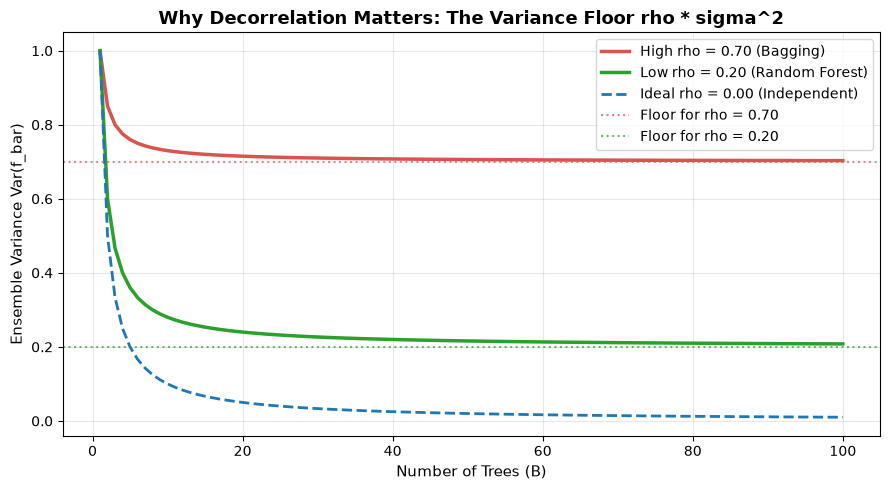

In [4]:
# Plot ensemble variance vs number of trees for different correlations rho
B_range = np.arange(1, 101)
sigma2 = 1.0

rho_high = 0.70   # Typical for Bagging (trees look similar)
rho_low = 0.20    # Typical for Random Forests (feature subsampling decorrelates)
rho_zero = 0.00   # Theoretical ideal (perfect independence)

var_high = rho_high * sigma2 + (1 - rho_high) * sigma2 / B_range
var_low  = rho_low  * sigma2 + (1 - rho_low)  * sigma2 / B_range
var_zero = rho_zero * sigma2 + (1 - rho_zero) * sigma2 / B_range

plt.figure(figsize=(9, 5))
plt.plot(B_range, var_high, label="High rho = 0.70 (Bagging)", color="#d9534f", lw=2.5)
plt.plot(B_range, var_low,  label="Low rho = 0.20 (Random Forest)", color="#2ca02c", lw=2.5)
plt.plot(B_range, var_zero, label="Ideal rho = 0.00 (Independent)", color="#1f77b4", lw=2, ls="--")
plt.axhline(rho_high * sigma2, color="#d9534f", ls=":", alpha=0.7, label="Floor for rho = 0.70")
plt.axhline(rho_low * sigma2,  color="#2ca02c", ls=":", alpha=0.7, label="Floor for rho = 0.20")
plt.xlabel("Number of Trees (B)", fontsize=11)
plt.ylabel("Ensemble Variance Var(f_bar)", fontsize=11)
plt.title("Why Decorrelation Matters: The Variance Floor rho * sigma^2", fontsize=13, fontweight="bold")
plt.legend(frameon=True, fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**What we just saw**:
The red curve (high correlation $\rho = 0.70$) rapidly flattens out around $0.70$. Adding more trees beyond 20 produces zero variance benefit!
The green curve (Random Forest $\rho = 0.20$) continues dropping all the way to $0.20$. That massive gap between $0.70$ and $0.20$ is the direct benefit of feature subsampling!

#### How to Read This Plot
- **Axes**: The horizontal axis ($X$) shows the number of trees ($B$) in the ensemble from 1 to 100. The vertical axis ($Y$) shows the resulting prediction variance.
- **What a Good Result Looks Like**: The green curve descends steeply and settles at a low value near $0.20$.
- **What a Bad Result Looks Like**: The red curve hits a high horizontal ceiling (the dotted line at $0.70$) very early, proving that adding more trees cannot overcome high correlation.
- **What This Plot Tells Us**: Bagging hits a wall because its trees are correlated. To build a better ensemble, we must decorrelate the trees!

#### 6. Common Beginner Mistake
Thinking that you can fix a bad, correlated bagging ensemble by simply increasing `n_estimators=1000`. As our mathematical formula proves, once $B$ reaches ~50, the term $\frac{1-\rho}{B}\sigma^2$ is practically zero, and the remaining error is strictly $\rho \sigma^2$. More trees cannot beat the correlation floor!

#### 7. Quick Check Yourself Question
> **Question**: If trees in an ensemble have a pairwise correlation of $\rho = 0.50$ and individual variance $\sigma^2 = 10$, what is the minimum possible ensemble variance as the number of trees approaches infinity?
>
> <details>
> <summary><b>Click to see the answer</b></summary>
> <b>Minimum Variance = 5.0</b> (calculated as $ho \sigma^2 = 0.50 	imes 10 = 5.0$).
> </details>


---
### 📌 Recap of Step 1 in 3 Bullets
1. **Single deep trees have low bias but high variance**: They can learn intricate patterns, but they overfit and destabilize when trained on slightly different datasets.
2. **Averaging independent models divides variance by $B$**: $\text{Var}(\bar{f}) = \sigma^2 / B$.
3. **Correlated models hit a hard variance floor $\rho \sigma^2$**: Bagging creates correlated trees because strong features dominate every tree; **feature subsampling** is the crucial innovation that slashes $\rho$ and unlocks true ensemble power.

> **If you remember only one thing from Step 1**:
> *More trees reduce variance, but only feature subsampling lowers the correlation floor $\rho \sigma^2$ where trees get stuck.*
